# Third Practice

### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336

In [265]:
# Necessary libraries
import numpy as np
import math as math
import matplotlib.pyplot as plt

## 1. Introduction task

We define a set of samples from a linear model with high noise.

In [266]:
m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle), -math.sin(angle)], [math.sin(angle), math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
n = 100
np.random.seed(112358)
points = np.random.multivariate_normal(m,s,n)

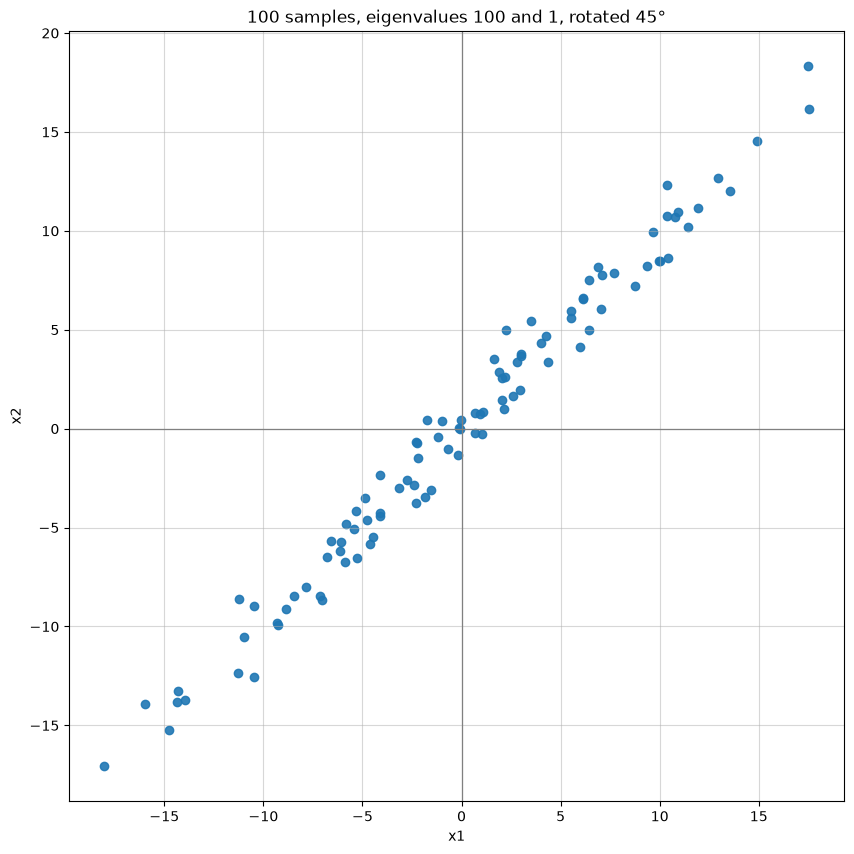

In [267]:
plt.figure(figsize=(10, 10))
plt.scatter(points[:, 0], points[:, 1], alpha=0.9)
plt.axhline(0, color="gray", lw=0.9)
plt.axvline(0, color="gray", lw=0.9)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"{n} samples, eigenvalues {lamb[0,0]} and {lamb[1,1]}, rotated {int(angle*180/math.pi)}°")
plt.grid(alpha=0.5)
plt.show()


We will now try to find the linear model that fits best the set of points we defined.

Our model will be $w_{1}x + w_{0}$. The goal is to find the parameters $w_{1}$ and $w_{0}$ that minimize a function that might as well be the `Least Squares` function and then use any type of _descent method_ that helps us minimize the function.

#### Loss function model

The loss function model, applied to our case, consists in minimizing $Q$ given a set of points $\{(x_{i},y_{i})\}_{i=1}^{m}$, where $Q$ is the defined as:

$$
Q = \frac{1}{2} \sum_{i=1}^{m}(\hat{y}_{i}-y_{i})^{2}
$$

With $\hat{y}_{i} = f(x_{i})$, the value we expect from our model.

In other words, we want to minimize:

$$
Q = \frac{1}{2} \sum_{i=1}^{m}(w_{1}x_{i} + w_{0} - y_{i})^{2}
$$

To do so, we will use the tools from sessions 1 and 2. We consider $Q(w) = Q(w_{0}, w_{1})$ the function to minimize.

As we have done repeatedly in the past, we will calculate the gradient, skipping the calculations for the sake of simplicity and _cleanness_.

$$
\nabla Q =
\begin{pmatrix}
\dfrac{\partial Q}{\partial w_0} \\[2ex]
\dfrac{\partial Q}{\partial w_1}
\end{pmatrix}
=
\begin{pmatrix}
\displaystyle\sum_{i=1}^{m} (w_1 x_i + w_0 - y_i) \\[2ex]
\displaystyle\sum_{i=1}^{m} (w_1 x_i + w_0 - y_i)\,x_i
\end{pmatrix}
$$


### 1.1 Implement the Least Squares method

We will use backtracking to minimize $Q(w)$. We will be reusing the code from Session 2.

In [268]:
def LSM(array, w0, w1):
    return (1/2)*np.sum((w1 * array[:, 0] + w0 - array[:, 1])**2)

def LSM_grad(array, w0, w1):
    part_comu = w1 * array[:, 0] + w0 - array[:, 1]
    grad_w0 = np.sum(part_comu)
    grad_w1 = np.sum(part_comu * array[:, 0])
    return np.array([grad_w0, grad_w1])

# I made alpha really small in order to show how the model improves itself
def grad_desc_backtracking(f, grad_f, x0, x1, alpha0=0.001, tol=1e-5, max_iter=10000, alpha_min=1e-5):
    x = np.array([x0, x1])
    path = [x]
    alphas = []
    n_halvings = 0
    alpha = alpha0
    for k in range(max_iter):
        grad = grad_f(x)
        if np.linalg.norm(grad) < tol:
            break
        while f(x - alpha * grad) >= f(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        if f(x - alpha * grad) >= f(x): # if no advances are made and alpha has reached its minimum
            break
        x = x - alpha * grad
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

Model: w_0 = 0.0141, w_1 = 0.9730
This represents a 44.22º angle
466 iterations
2 halvings
LSM = 57.9240


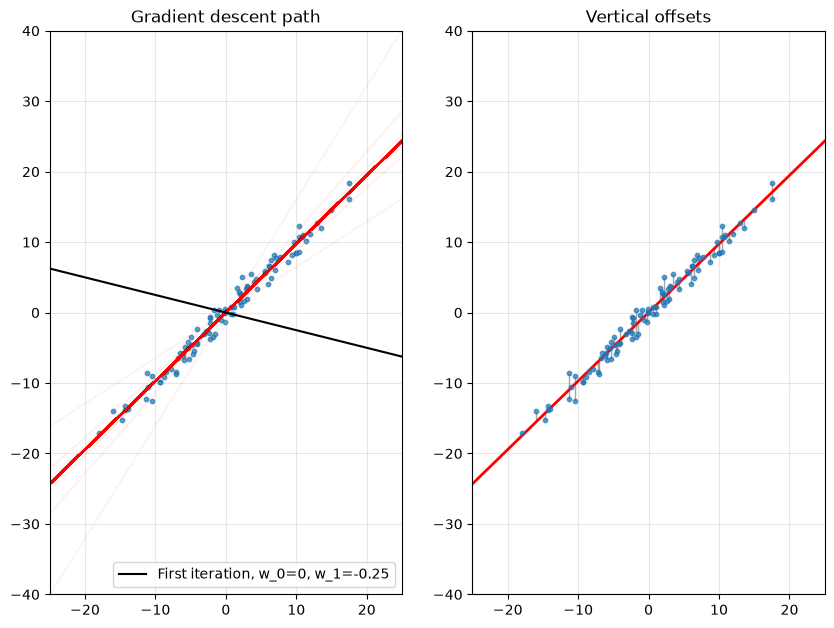

In [269]:
def f_lsm(w):
    return LSM(points, w[0], w[1])

def grad_f_lsm(w):
    return LSM_grad(points, w[0], w[1])

path_LSM, alphas_LSM, n_halvings_LSM = grad_desc_backtracking(f_lsm, grad_f_lsm, 0, -0.25)
angle_LSM = np.degrees(np.arctan(path_LSM[-1][1]))
print(f"Model: w_0 = {path_LSM[-1][0]:.4f}, w_1 = {path_LSM[-1][1]:.4f}\nThis represents a {angle_LSM:.2f}º angle\n{len(path_LSM)} iterations\n{n_halvings_LSM} halvings\nLSM = {f_lsm(path_LSM[-1]):.4f}")

results_LSM = {"w0": path_LSM[-1][0], "w1": path_LSM[-1][1], "angle": angle_LSM, "iters": len(path_LSM), "Q": f_lsm(path_LSM[-1])}

w0_opt_LSM, w1_opt_LSM = path_LSM[-1]
xs_LSM, ys_LSM = points[:, 0], points[:, 1]
y_hat_LSM = w0_opt_LSM + w1_opt_LSM * xs_LSM
residuals_LSM = ys_LSM - y_hat_LSM

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
#Plot 1
axs[0].scatter(xs_LSM, ys_LSM, alpha=0.7, s=10)
for k in range(len(path_LSM)):
    w0, w1 = path_LSM[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.05 + 0.5 * k / (len(path_LSM) - 1))
axs[0].axline((0,path_LSM[0][0]), slope=path_LSM[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].legend(loc="lower right")
axs[0].set_title("Gradient descent path")

#Plot 2
axs[1].vlines(xs_LSM, y_hat_LSM, ys_LSM, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_LSM, ys_LSM, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_LSM), slope=w1_opt_LSM, color="red", lw=2)
axs[1].set_title("Vertical offsets")

for ax in axs:
    ax.set_xlim(-25, 25)
    ax.set_ylim(-40, 40)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

### 1.2 Outliers influence

In order to show the sensitivity of our model to outliers we will edit one point of our dataset. This point will now be found at $\left[-40,20\right]$. Then we will compare both models and check the difference when just one point is an outlier.

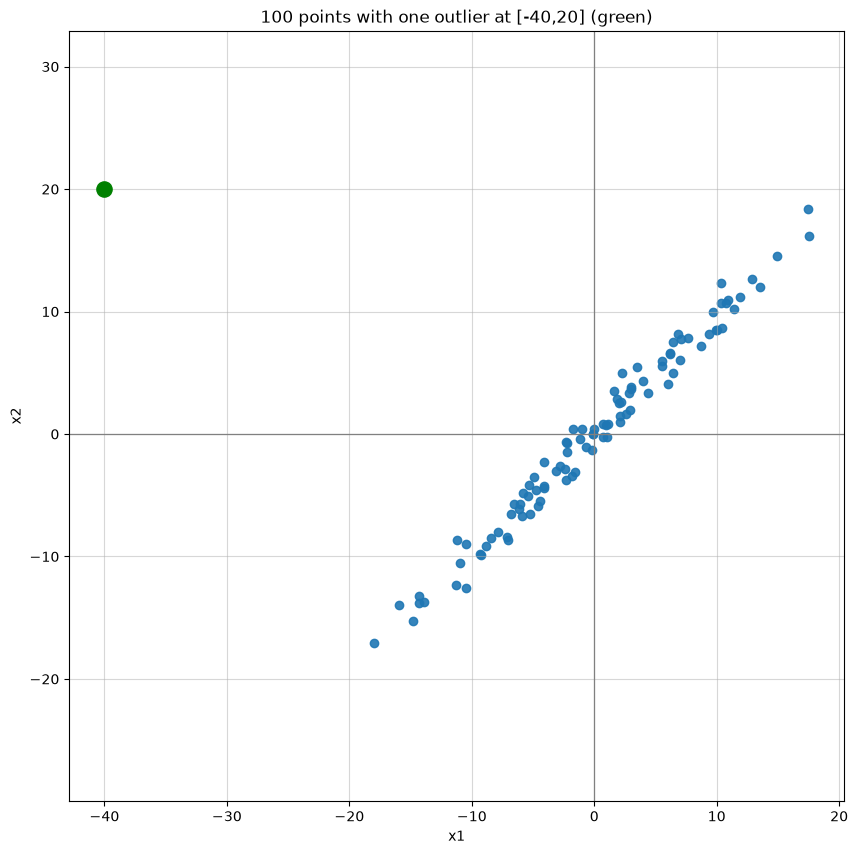

In [270]:
points_one_outlier = points.copy()
points_one_outlier[1] = [-40,20]

plt.figure(figsize=(10, 10))
plt.scatter(points_one_outlier[:, 0], points_one_outlier[:, 1], alpha=0.9)
plt.scatter(*points_one_outlier[1], color="green", s=120, zorder=3)
plt.axhline(0, color="gray", lw=0.9)
plt.axvline(0, color="gray", lw=0.9)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"100 points with one outlier at [-40,20] (green)")
plt.grid(alpha=0.5)
plt.show()

Now we will repeat section 1.1 but with the edited dataset

Model: w_0 = 0.4819, w_1 = 0.6670
This represents a 33.70º angle
552 iterations
7 halvings
LSM = 1418.3088


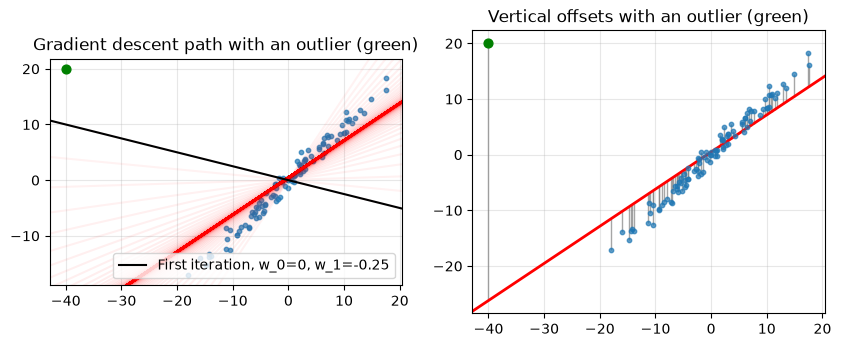

In [271]:
def f_lsm(w):
    return LSM(points_one_outlier, w[0], w[1])

def grad_f_lsm(w):
    return LSM_grad(points_one_outlier, w[0], w[1])

path_LSM_outlier, alphas_LSM_outlier, n_halvings_LSM_outlier = grad_desc_backtracking(f_lsm, grad_f_lsm, 0, -0.25)
angle_LSM_outlier = np.degrees(np.arctan(path_LSM_outlier[-1][1]))
print(f"Model: w_0 = {path_LSM_outlier[-1][0]:.4f}, w_1 = {path_LSM_outlier[-1][1]:.4f}\nThis represents a {angle_LSM_outlier:.2f}º angle\n{len(path_LSM_outlier)} iterations\n{n_halvings_LSM_outlier} halvings\nLSM = {f_lsm(path_LSM_outlier[-1]):.4f}")

results_LSM_outlier = {"w0": path_LSM_outlier[-1][0], "w1": path_LSM_outlier[-1][1], "angle": angle_LSM_outlier, "iters": len(path_LSM_outlier), "Q": f_lsm(path_LSM_outlier[-1])}

w0_opt_LSM_outlier, w1_opt_LSM_outlier = path_LSM_outlier[-1]
xs_LSM_outlier, ys_LSM_outlier = points_one_outlier[:, 0], points_one_outlier[:, 1]
y_hat_LSM_outlier = w0_opt_LSM_outlier + w1_opt_LSM_outlier * xs_LSM_outlier
residuals_LSM_outlier = ys_LSM_outlier - y_hat_LSM_outlier

fig, axs = plt.subplots(1, 2, figsize=(10, 8))

#Plot 1
axs[0].scatter(xs_LSM_outlier, ys_LSM_outlier, alpha=0.7, s=10)
for k in range(len(path_LSM_outlier)):
    w0, w1 = path_LSM_outlier[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.05 + 0.5 * k / (len(path_LSM_outlier) - 1))
axs[0].axline((0,path_LSM_outlier[0][0]), slope=path_LSM_outlier[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[0].legend(loc="lower right")
axs[0].set_title("Gradient descent path with an outlier (green)")

#Plot 2
axs[1].vlines(xs_LSM_outlier, y_hat_LSM_outlier, ys_LSM_outlier, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_LSM_outlier, ys_LSM_outlier, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_LSM_outlier), slope=w1_opt_LSM_outlier, color="red", lw=2)
axs[1].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[1].set_title("Vertical offsets with an outlier (green)")

for ax in axs:
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

We compare the results obtained with and without the outlier:

In [272]:
Q_LSM = LSM(points, w0_opt_LSM, w1_opt_LSM)
Q_LSM_outlier = LSM(points_one_outlier, w0_opt_LSM_outlier, w1_opt_LSM_outlier)

print(f"{'':>10} | {'No outliers':>11} | {'With outliers':>13} | {'Difference %':>12}")
print("-" * 56)
print(f"{'w0':>10} | {w0_opt_LSM:>11.4f} | {w0_opt_LSM_outlier:>13.4f} | {100 * (w0_opt_LSM_outlier - w0_opt_LSM) / abs(w0_opt_LSM):>+11.2f}%")
print(f"{'w1':>10} | {w1_opt_LSM:>11.4f} | {w1_opt_LSM_outlier:>13.4f} | {100 * (w1_opt_LSM_outlier - w1_opt_LSM) / abs(w1_opt_LSM):>+11.2f}%")
print(f"{'Angle':>10} | {angle_LSM:>11.2f} | {angle_LSM_outlier:>13.2f} | {100 * (angle_LSM_outlier - angle_LSM) / abs(angle_LSM):>+11.2f}%")
print(f"{'Iterations':>10} | {len(path_LSM):>11} | {len(path_LSM_outlier):>13} | {100 * (len(path_LSM_outlier) - len(path_LSM)) / len(path_LSM):>+11.2f}%")
print(f"{'Q(w)':>10} | {Q_LSM:>11.2f} | {Q_LSM_outlier:>13.2f} | {100 * (Q_LSM_outlier - Q_LSM) / abs(Q_LSM):>+11.2f}%")


           | No outliers | With outliers | Difference %
--------------------------------------------------------
        w0 |      0.0141 |        0.4819 |    +3321.40%
        w1 |      0.9730 |        0.6670 |      -31.45%
     Angle |       44.22 |         33.70 |      -23.78%
Iterations |         466 |           552 |      +18.45%
      Q(w) |       57.92 |       1418.31 |    +2348.57%


Without the outlier the model recovers the structure of the data almost perfectly. The points were generated along the 45º direction, meaning $w_{1} = 1$ and $w_{0} = 0$ and we obtain $w_1 = 0.9643$ (43.96º) and $w_0 = 0.1447$.
Changing a single point out of 100 rotates the line by about 12º, and the slope drops about 30%.

With the no outlier model, the point $[-40, 20]$ would contribute approximately $\frac{1}{2}\cdot 58^2 \approx 1700$ to $Q$ on its own, more than 20 times the $Q$ of all the other points together (73.24). Since the gradient of each term is proportional to its residual, the outlier dominates the descent direction, and the optimum becomes a line that sacrifices the fit of the 99 non-outlier points to reduce that single error.

The final $Q$ increases by about 1700%, in the outlier model the outlier still has a contribution of $\frac{1}{2}44^{2}\approx 970$, so the remaining 99 points contribute about 390, roughly five times worse than in the no outliers model.

The method needs about 4 times as many iterations from 561 to 2331. The Least Squares model is very sensitive to outliers, one bad sample has been enough to change the fitted model.

We will now change more points of the original dataset to assess the influence of having more than one outlier. Besides the outlier at $\left[-40,20\right]$, we move four more points to $\left[-33,35\right]$, $\left[41,-22\right]$, $\left[10,-17\right]$ and $\left[-11,-55\right]$, so we have five outliers out of 100 points.

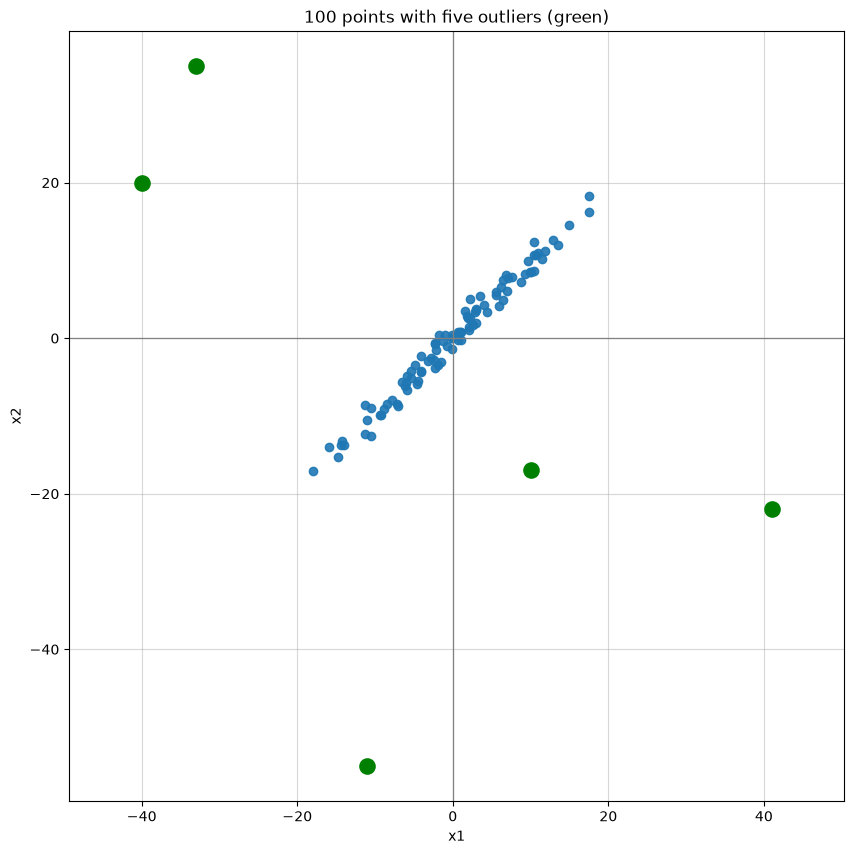

In [273]:
points_more_outliers = points_one_outlier.copy()
points_more_outliers[2] = [-33,35]
points_more_outliers[3] = [41,-22]
points_more_outliers[4] = [10,-17]
points_more_outliers[5] = [-11,-55]
outliers_idx = [1, 2, 3, 4, 5]

plt.figure(figsize=(10, 10))
plt.scatter(points_more_outliers[:, 0], points_more_outliers[:, 1], alpha=0.9)
plt.scatter(points_more_outliers[outliers_idx, 0], points_more_outliers[outliers_idx, 1], color="green", s=120, zorder=3)
plt.axhline(0, color="gray", lw=0.9)
plt.axvline(0, color="gray", lw=0.9)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"100 points with five outliers (green)")
plt.grid(alpha=0.5)
plt.show()

Now we will repeat section 1.1 with the five outliers dataset

Model: w_0 = -0.1869, w_1 = 0.3157
This represents a 17.52º angle
969 iterations
7 halvings
LSM = 5029.3198


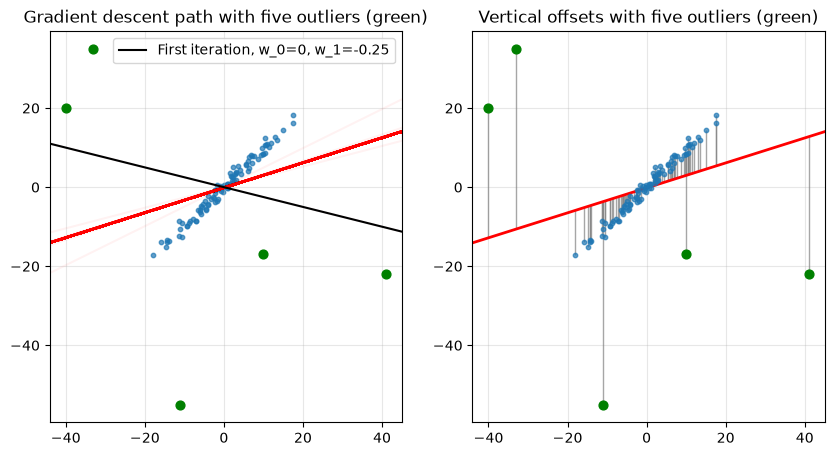

In [274]:
def f_lsm(w):
    return LSM(points_more_outliers, w[0], w[1])

def grad_f_lsm(w):
    return LSM_grad(points_more_outliers, w[0], w[1])

path_LSM_more_outliers, alphas_LSM_more_outliers, n_halvings_LSM_more_outliers = grad_desc_backtracking(f_lsm, grad_f_lsm, 0, -0.25)
angle_LSM_more_outliers = np.degrees(np.arctan(path_LSM_more_outliers[-1][1]))
print(f"Model: w_0 = {path_LSM_more_outliers[-1][0]:.4f}, w_1 = {path_LSM_more_outliers[-1][1]:.4f}\nThis represents a {angle_LSM_more_outliers:.2f}º angle\n{len(path_LSM_more_outliers)} iterations\n{n_halvings_LSM_more_outliers} halvings\nLSM = {f_lsm(path_LSM_more_outliers[-1]):.4f}")

results_LSM_more_outliers = {"w0": path_LSM_more_outliers[-1][0], "w1": path_LSM_more_outliers[-1][1], "angle": angle_LSM_more_outliers, "iters": len(path_LSM_more_outliers), "Q": f_lsm(path_LSM_more_outliers[-1])}

w0_opt_LSM_more_outliers, w1_opt_LSM_more_outliers = path_LSM_more_outliers[-1]
xs_LSM_more_outliers, ys_LSM_more_outliers = points_more_outliers[:, 0], points_more_outliers[:, 1]
y_hat_LSM_more_outliers = w0_opt_LSM_more_outliers + w1_opt_LSM_more_outliers * xs_LSM_more_outliers
residuals_LSM_more_outliers = ys_LSM_more_outliers - y_hat_LSM_more_outliers

fig, axs = plt.subplots(1, 2, figsize=(10, 8))

#Plot 1
axs[0].scatter(xs_LSM_more_outliers, ys_LSM_more_outliers, alpha=0.7, s=10)
for k in range(len(path_LSM_more_outliers)):
    w0, w1 = path_LSM_more_outliers[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.05 + 0.5 * k / (len(path_LSM_more_outliers) - 1))
axs[0].axline((0,path_LSM_more_outliers[0][0]), slope=path_LSM_more_outliers[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
# zorder=6 draws the outliers over the legend
axs[0].scatter(points_more_outliers[outliers_idx, 0], points_more_outliers[outliers_idx, 1], color="green", s=40, zorder=6)
axs[0].legend(loc="upper right")
axs[0].set_title("Gradient descent path with five outliers (green)")

#Plot 2
axs[1].vlines(xs_LSM_more_outliers, y_hat_LSM_more_outliers, ys_LSM_more_outliers, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_LSM_more_outliers, ys_LSM_more_outliers, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_LSM_more_outliers), slope=w1_opt_LSM_more_outliers, color="red", lw=2)
axs[1].scatter(points_more_outliers[outliers_idx, 0], points_more_outliers[outliers_idx, 1], color="green", s=40, zorder=3)
axs[1].set_title("Vertical offsets with five outliers (green)")

for ax in axs:
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

We compare the results obtained with no outliers, one outlier and five outliers:

In [275]:
Q_LSM_more_outliers = LSM(points_more_outliers, w0_opt_LSM_more_outliers, w1_opt_LSM_more_outliers)

# Difference in % with respect to the model without outliers
def diff_pct(new, old):
    return 100 * (new - old) / abs(old)

rows = [
    ("w0",         [w0_opt_LSM, w0_opt_LSM_outlier, w0_opt_LSM_more_outliers], ".4f"),
    ("w1",         [w1_opt_LSM, w1_opt_LSM_outlier, w1_opt_LSM_more_outliers], ".4f"),
    ("Angle",      [angle_LSM, angle_LSM_outlier, angle_LSM_more_outliers], ".2f"),
    ("Iterations", [len(path_LSM), len(path_LSM_outlier), len(path_LSM_more_outliers)], "d"),
    ("Q(w)",       [Q_LSM, Q_LSM_outlier, Q_LSM_more_outliers], ".2f"),
]

print(f"{'':>10} | {'No outliers':>11} | {'One outlier':>11} | {'Five outliers':>13} | {'Diff % (one)':>12} | {'Diff % (five)':>13}")
print("-" * 86)
for name, v, fmt in rows:
    print(f"{name:>10} | {v[0]:>11{fmt}} | {v[1]:>11{fmt}} | {v[2]:>13{fmt}} | {diff_pct(v[1], v[0]):>+11.2f}% | {diff_pct(v[2], v[0]):>+12.2f}%")

           | No outliers | One outlier | Five outliers | Diff % (one) | Diff % (five)
--------------------------------------------------------------------------------------
        w0 |      0.0141 |      0.4819 |       -0.1869 |    +3321.40% |     -1426.63%
        w1 |      0.9730 |      0.6670 |        0.3157 |      -31.45% |       -67.55%
     Angle |       44.22 |       33.70 |         17.52 |      -23.78% |       -60.37%
Iterations |         466 |         552 |           969 |      +18.45% |      +107.94%
      Q(w) |       57.92 |     1418.31 |       5029.32 |    +2348.57% |     +8582.62%


Adding 4 more outliers caused for the method to behave even worse, the line rotates from $44.22º$ to $17.52º$, about $27º$, more than twice the rotation caused by a single outlier, and the slope drops about 68%. The intercept goes from $w_{0} = 0.0141$ to $w_{0} = -0.1869$.

With the no outlier model, the five outliers would contribute approximately $\frac{1}{2}\left(58.91^{2} + 67.10^{2} + 61.91^{2} + 26.74^{2} + 44.31^{2}\right) \approx 7240$ to $Q$, about 128 times the $Q$ of the other 95 points together ($56.58$).

The final $Q$ increases by about $8600%$, in the five outliers model the outliers still have a contribution of about $3700$, so the remaining 95 points contribute about $1330$, roughly 23 times worse than in the no outliers model, whilst with one outlier the non-outlier points were about 6 times worse. Even at the optimum, the five outliers make up about 74% of $Q$.

The method needs about twice as many iterations, from 466 to 969. With only 5 of the points being outliers, the Least Squares model no longer recovers the structure of the data, the fitted line is determined more by the 5 outliers than by the other 95 points.

## 2 Robust function

We have seen the sensitivity of the Least Squares Method. We shall use functions that are more robust to outliers. The general function we will minimize is:

$$
\sum_{i=1}^{m} \rho(u_{i})
$$

where $u_{i}$ is the prediction error of the point $i$. in our case:

$$
u_{i} = \hat{y}_{i} - y_{i} = w_{1}x_{i} + w_{0} - y_{i}
$$

and $\rho(u)$ is a robust error function. The Least Squares method is just the case $\rho(u) = \frac{1}{2}u^{2}$.

We will use the Cauchy function, defined as:

$$
\rho(u) = \frac{c^{2}}{2} \log\left[1 + \left(\frac{u}{c}\right)^{2}\right]
$$

where $c \in \mathbb{R}$ is a parameter, we will take $c = 1$. Applied to our model, the function to minimize is:

$$
C(w_{0}, w_{1}) = \frac{c^{2}}{2} \sum_{i=1}^{m} \log\left[1 + \frac{(w_{1}x_{i} + w_{0} - y_{i})^{2}}{c^{2}}\right]
$$

Using the chain rule, the derivative of $\rho$ with respect to $u$ is:

$$
\rho'(u) = \frac{c^{2}}{2} \cdot \frac{2u/c^{2}}{1 + (u/c)^{2}} = \frac{u}{1 + (u/c)^{2}}
$$

and since $\dfrac{\partial u_{i}}{\partial w_{0}} = 1$ and $\dfrac{\partial u_{i}}{\partial w_{1}} = x_{i}$, the gradient is:

$$
\nabla C =
\begin{pmatrix}
\dfrac{\partial C}{\partial w_0} \\[2ex]
\dfrac{\partial C}{\partial w_1}
\end{pmatrix}
=
\begin{pmatrix}
\displaystyle\sum_{i=1}^{m} \frac{w_1 x_i + w_0 - y_i}{1 + \left(\frac{w_1 x_i + w_0 - y_i}{c}\right)^{2}} \\[4ex]
\displaystyle\sum_{i=1}^{m} \frac{w_1 x_i + w_0 - y_i}{1 + \left(\frac{w_1 x_i + w_0 - y_i}{c}\right)^{2}}\,x_i
\end{pmatrix}
$$


In [276]:
def cauchy(array, w0, w1, c=1):
    return ((c**2)/2)*np.sum(np.log(1+((w1 * array[:, 0] + w0 - array[:, 1])**2)/(c**2)))

def cauchy_grad(array, w0, w1, c=1):
    part_comu = w1 * array[:, 0] + w0 - array[:, 1]
    weight = part_comu / (1 + (part_comu**2)/(c**2))
    grad_w0 = np.sum(weight)
    grad_w1 = np.sum(weight * array[:, 0])
    return np.array([grad_w0, grad_w1])


### 2.1 Plot the least squares function and compare it with the Cauchy function

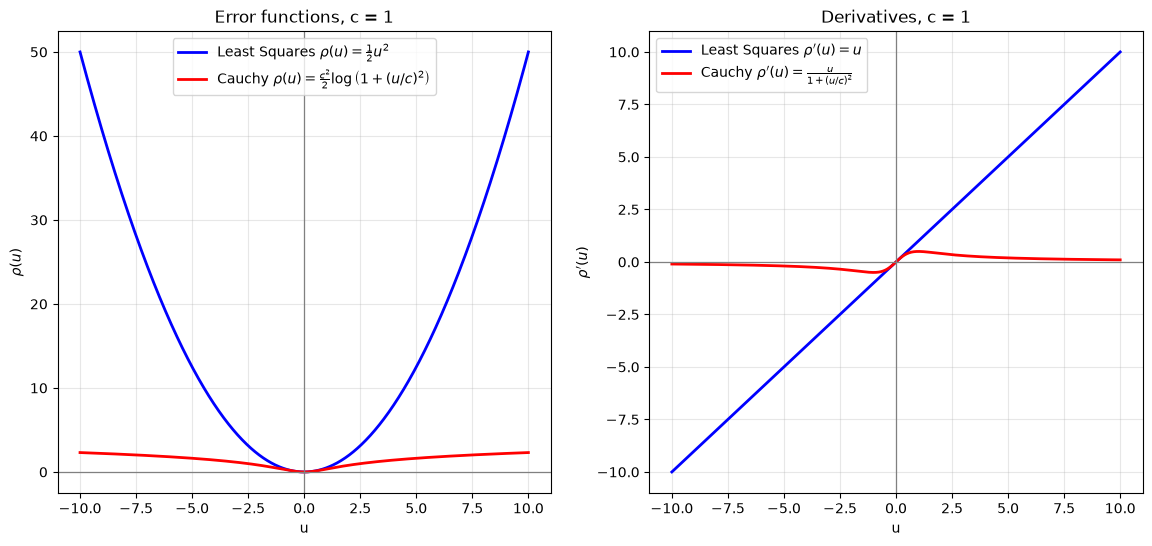

Cauchy(10)        = 0.0990
Least Squares(10) = 10


In [277]:
u = np.linspace(-10, 10, 1000)
c = 1

rho_lsm = (1/2) * u**2
rho_cauchy = ((c**2)/2) * np.log(1 + (u/c)**2)

# Derivatives: how much each error "pulls" on the gradient
drho_lsm = u
drho_cauchy = u / (1 + (u/c)**2)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1
axs[0].plot(u, rho_lsm, color="blue", lw=2, label=r"Least Squares $\rho(u) = \frac{1}{2}u^2$")
axs[0].plot(u, rho_cauchy, color="red", lw=2, label=r"Cauchy $\rho(u) = \frac{c^2}{2}\log\left(1 + (u/c)^2\right)$")
axs[0].set_xlabel("u")
axs[0].set_ylabel(r"$\rho(u)$")
axs[0].legend(loc="upper center")
axs[0].set_title(f"Error functions, c = {c}")

# Plot 2
axs[1].plot(u, drho_lsm, color="blue", lw=2, label=r"Least Squares $\rho'(u) = u$")
axs[1].plot(u, drho_cauchy, color="red", lw=2, label=r"Cauchy $\rho'(u) = \frac{u}{1 + (u/c)^2}$")
axs[1].set_xlabel("u")
axs[1].set_ylabel(r"$\rho'(u)$")
axs[1].legend(loc="upper left")
axs[1].set_title(f"Derivatives, c = {c}")

for ax in axs:
    ax.axhline(0, color="gray", lw=0.9)
    ax.axvline(0, color="gray", lw=0.9)
    ax.grid(alpha=0.3)
plt.show()

print(f"Cauchy(10)        = {10 / (1 + (10/c)**2):.4f}\nLeast Squares(10) = {10:.0f}")


We can see how the contribution of outliers in the least squares method increases as the outlier is further away from the "good" points. On the other hand, the Cauchy function increases slowly, as expected from a logarithm.

For small $u$'s both models are very close, we can see the same pattern for the derivatives. By the Taylor expansion of the logarithm, taught in calculus and real analysis courses, we know that for small values of $x$, $\log(1+x) \sim x$, therefore, by having $c=1$ and $u$ close to $0$ we see that $\frac{1}{2}\log(1+u^{2}) \sim \frac{1}{2}u^{2}$, so they coincide. The same can be concluded in the derivatives, $\frac{u}{1+u^{2}} \sim u$, the same derivative as the Least Squares.

More importantly, we see that the derivative of the Cauchy function decreases to $0$ as $u$ increases (in absolute value), being under $0.1$ at just $u=10$. Whilst the Least Squares derivative returns $10$ for the same $u$, a value $100$ times larger. This means that a value at (vertical) distance $10$ from a particular step from the model influences $100$ times less the next step of the gradient descent.

### 2.2, 2.3 & 2.4 Cauchy vs LSM

Now we will compare how backtracking differs between the Least Squares method and the Cauchy function. As we have just seen, we are expecting for the Cauchy to behave similarly to LSM when all the points are "good" and to not vary as much whenever outliers appear.

Let's define its gradient descent:

Model: w_0 = 0.0101, w_1 = 0.9732
This represents a 44.22º angle
330 iterations
0 halvings
Q = 30.6221


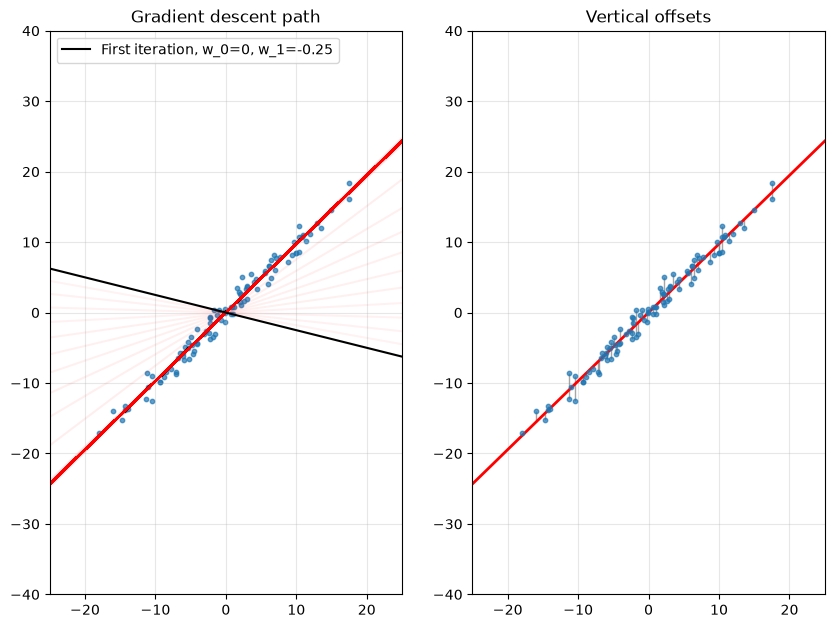

In [278]:
def f_cauchy(w):
    return cauchy(points, w[0], w[1])

def grad_f_cauchy(w):
    return cauchy_grad(points, w[0], w[1])

path_Cauchy, alphas_Cauchy, n_halvings_Cauchy = grad_desc_backtracking(f_cauchy, grad_f_cauchy, 0, -0.25)
angle_Cauchy = np.degrees(np.arctan(path_Cauchy[-1][1]))
print(f"Model: w_0 = {path_Cauchy[-1][0]:.4f}, w_1 = {path_Cauchy[-1][1]:.4f}\nThis represents a {angle_Cauchy:.2f}º angle\n{len(path_Cauchy)} iterations\n{n_halvings_Cauchy} halvings\nQ = {f_cauchy(path_Cauchy[-1]):.4f}")

results_Cauchy = {"w0": path_Cauchy[-1][0], "w1": path_Cauchy[-1][1], "angle": angle_Cauchy, "iters": len(path_Cauchy), "Q": f_cauchy(path_Cauchy[-1])}

w0_opt_Cauchy, w1_opt_Cauchy = path_Cauchy[-1]
xs_Cauchy, ys_Cauchy = points[:, 0], points[:, 1]
y_hat_Cauchy = w0_opt_Cauchy + w1_opt_Cauchy * xs_Cauchy
residuals_Cauchy = ys_Cauchy - y_hat_Cauchy

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
#Plot 1
axs[0].scatter(xs_Cauchy, ys_Cauchy, alpha=0.7, s=10)
for k in range(len(path_Cauchy)):
    w0, w1 = path_Cauchy[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.05 + 0.5 * k / (len(path_Cauchy) - 1))
axs[0].axline((0,path_Cauchy[0][0]), slope=path_Cauchy[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].legend(loc="upper left")
axs[0].set_title("Gradient descent path")

#Plot 2
axs[1].vlines(xs_Cauchy, y_hat_Cauchy, ys_Cauchy, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_Cauchy, ys_Cauchy, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_Cauchy), slope=w1_opt_Cauchy, color="red", lw=2)
axs[1].set_title("Vertical offsets")

for ax in axs:
    ax.set_xlim(-25, 25)
    ax.set_ylim(-40, 40)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

We repeat the process adding an outlier at $[-40, 20]$. We will explain the conclusions after this.

Model: w_0 = -0.0055, w_1 = 0.9716
This represents a 44.18º angle
398 iterations
0 halvings
Q = 34.5721


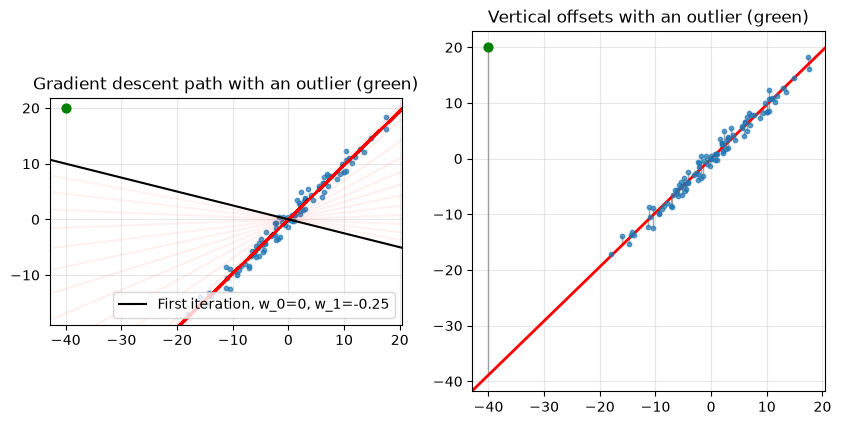

In [279]:
def f_cauchy(w, c=1):
    return cauchy(points_one_outlier, w[0], w[1], c)

def grad_f_cauchy(w, c=1):
    return cauchy_grad(points_one_outlier, w[0], w[1], c)

path_Cauchy_outlier, alphas_Cauchy_outlier, n_halvings_Cauchy_outlier = grad_desc_backtracking(f_cauchy, grad_f_cauchy, 0, -0.25)
angle_Cauchy_outlier = np.degrees(np.arctan(path_Cauchy_outlier[-1][1]))
print(f"Model: w_0 = {path_Cauchy_outlier[-1][0]:.4f}, w_1 = {path_Cauchy_outlier[-1][1]:.4f}\nThis represents a {angle_Cauchy_outlier:.2f}º angle\n{len(path_Cauchy_outlier)} iterations\n{n_halvings_Cauchy_outlier} halvings\nQ = {f_cauchy(path_Cauchy_outlier[-1]):.4f}")

results_Cauchy_outlier = {"w0": path_Cauchy_outlier[-1][0], "w1": path_Cauchy_outlier[-1][1], "angle": angle_Cauchy_outlier, "iters": len(path_Cauchy_outlier), "Q": f_cauchy(path_Cauchy_outlier[-1])}

w0_opt_Cauchy_outlier, w1_opt_Cauchy_outlier = path_Cauchy_outlier[-1]
xs_Cauchy_outlier, ys_Cauchy_outlier = points_one_outlier[:, 0], points_one_outlier[:, 1]
y_hat_Cauchy_outlier = w0_opt_Cauchy_outlier + w1_opt_Cauchy_outlier * xs_Cauchy_outlier
residuals_Cauchy_outlier = ys_Cauchy_outlier - y_hat_Cauchy_outlier

fig, axs = plt.subplots(1, 2, figsize=(10, 8))

#Plot 1
axs[0].scatter(xs_Cauchy_outlier, ys_Cauchy_outlier, alpha=0.7, s=10)
for k in range(len(path_Cauchy_outlier)):
    w0, w1 = path_Cauchy_outlier[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.05 + 0.5 * k / (len(path_Cauchy_outlier) - 1))
axs[0].axline((0,path_Cauchy_outlier[0][0]), slope=path_Cauchy_outlier[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[0].legend(loc="lower right")
axs[0].set_title("Gradient descent path with an outlier (green)")

#Plot 2
axs[1].vlines(xs_Cauchy_outlier, y_hat_Cauchy_outlier, ys_Cauchy_outlier, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_Cauchy_outlier, ys_Cauchy_outlier, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_Cauchy_outlier), slope=w1_opt_Cauchy_outlier, color="red", lw=2)
axs[1].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[1].set_title("Vertical offsets with an outlier (green)")

for ax in axs:
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

In [280]:
# SSE on all the points and on the 99 non-outlier points (index 1 is the outlier), to compare both methods with the same measure
def sse(data, w0, w1):
    return np.sum((w1 * data[:, 0] + w0 - data[:, 1])**2)

mask = np.arange(len(points)) != 1
def sse_clean(w0, w1):
    return np.sum((w1 * points[mask, 0] + w0 - points[mask, 1])**2)

rows = [
    ("w0",             [w0_opt_LSM, w0_opt_Cauchy, w0_opt_LSM_outlier, w0_opt_Cauchy_outlier], ".4f"),
    ("w1",             [w1_opt_LSM, w1_opt_Cauchy, w1_opt_LSM_outlier, w1_opt_Cauchy_outlier], ".4f"),
    ("Angle (º)",      [angle_LSM, angle_Cauchy, angle_LSM_outlier, angle_Cauchy_outlier], ".2f"),
    ("Iterations",     [len(path_LSM), len(path_Cauchy), len(path_LSM_outlier), len(path_Cauchy_outlier)], "d"),
    ("Halvings",       [n_halvings_LSM, n_halvings_Cauchy, n_halvings_LSM_outlier, n_halvings_Cauchy_outlier], "d"),
    ("Q",              [results_LSM["Q"], results_Cauchy["Q"], results_LSM_outlier["Q"], results_Cauchy_outlier["Q"]], ".2f"),
    ("SSE",            [sse(points, w0_opt_LSM, w1_opt_LSM), sse(points, w0_opt_Cauchy, w1_opt_Cauchy),
                        sse(points_one_outlier, w0_opt_LSM_outlier, w1_opt_LSM_outlier), sse(points_one_outlier, w0_opt_Cauchy_outlier, w1_opt_Cauchy_outlier)], ".2f"),
    ("SSE 99 points",  [sse_clean(w0_opt_LSM, w1_opt_LSM), sse_clean(w0_opt_Cauchy, w1_opt_Cauchy),
                        sse_clean(w0_opt_LSM_outlier, w1_opt_LSM_outlier), sse_clean(w0_opt_Cauchy_outlier, w1_opt_Cauchy_outlier)], ".2f"),
]

def diff_abs(lsm, cauchy):
    return abs(cauchy - lsm)

print(f"{'':>14} | {'Normal dataset':^38} | {'Outlier dataset':^38}")
print(f"{'':>14} | {'LSM':>10} | {'Cauchy':>10} | {'Diff (abs)':>12} | {'LSM':>10} | {'Cauchy':>10} | {'Diff (abs)':>12}")
print("-" * 97)
for name, v, fmt in rows:
    dfmt = ".0f" if fmt == "d" else ".3f"
    print(f"{name:>14} | {v[0]:>10{fmt}} | {v[1]:>10{fmt}} | {diff_abs(v[0], v[1]):>12{dfmt}} | "
          f"{v[2]:>10{fmt}} | {v[3]:>10{fmt}} | {diff_abs(v[2], v[3]):>12{dfmt}}")

print("\nSSE is the sum of squared distances of all the points (so 2 times Q).\nSSE 99 points is the sum of squared distances of the non-outlier points.")


               |             Normal dataset             |            Outlier dataset            
               |        LSM |     Cauchy |   Diff (abs) |        LSM |     Cauchy |   Diff (abs)
-------------------------------------------------------------------------------------------------
            w0 |     0.0141 |     0.0101 |        0.004 |     0.4819 |    -0.0055 |        0.487
            w1 |     0.9730 |     0.9732 |        0.000 |     0.6670 |     0.9716 |        0.305
     Angle (º) |      44.22 |      44.22 |        0.005 |      33.70 |      44.18 |       10.471
    Iterations |        466 |        330 |          136 |        552 |        398 |          154
      Halvings |          2 |          0 |            2 |          7 |          0 |            7
             Q |      57.92 |      30.62 |       27.302 |    1418.31 |      34.57 |     1383.737
           SSE |     115.85 |     115.85 |        0.002 |    2836.62 |    3581.35 |      744.733
 SSE 99 points |     115.58 |

#### Comparison between LSM and Cauchy with normal dataset

As we can see, with the normal dataset, both models end up yielding extremely similar models, with both $w_{0}$ and $w_{1}$ being less than $0.015$ apart between the two models. The final angle also coincides, with both being almost $45º$.

In terms of how the model performs at finding the minimum, we see that using the Cauchy method took longer but used just one halving in the backtracking gradient descent, meaning that using the Cauchy function, the method doesn't overshoot as much as with Least Squares.

We see that the function to minimize, $Q$, ended up smaller with the Cauchy function, this doesn't directly mean that Cauchy was better in this case. As stated before, both models yield almost the same solution, and Least Squares reached it faster.

To perform a better comparison, we compare the sum of squared distances for both models' solutions. As expected, both solutions end up adding almost the same amount, $187.47$ for Least Squares and $187.63$ for Cauchy, a difference of just $0.157$.

#### Comparison between LSM and Cauchy with the outlier dataset

As we can see, the outlier has a big impact on the Least Squares model whilst the Cauchy model barely changes. Least Squares moves $w_{0}$ to $0.8114$ and $w_{1}$ to $0.5841$, so the angle drops from almost $45º$ to $30.29º$, deviating from the real model. On the other hand, Cauchy ends up with $w_{0} = -0.1118$ and $w_{1} = 0.9896$, an angle of $44.70º$, practically the same as the one it obtained without the outlier.

The same happens with the number of iterations. Least Squares needs $2474$ iterations, more than $3$ times the amount it needed before, as the outlier dominates the gradient and the method is dragged away from the direction of the "good" points. Cauchy needs $931$ iterations, almost the same as before, and it still used just one halving, whilst Least Squares used $7$.

The value of the function to minimize shows the same pattern. $Q$ goes from $94.54$ to $1367.37$ in Least Squares, whilst in Cauchy it goes from $36.92$ to $40.54$. Again, these two values can't be compared directly, but it shows that the outlier almost doesn't contribute to the Cauchy function, as the logarithm grows slowly, as seen in section 2.1.

To perform a fair comparison we use again the sum of squared distances of the $99$ points that are not the outlier. Least Squares ends up with $924.01$, about $5$ times worse than the $187.47$ it got without the outlier. Cauchy ends up with almost the same value as before, so the Cauchy function has basically ignored the outlier. We conclude that Cauchy is a much more robust choice than Least Squares when the data might contain outliers, and that when there are none it gives almost the same solution as Least Squares.


### 2.5 Influence of different $c$ values in the Cauchy function

Normal dataset
       c |       w0 |       w1 | Angle (º) | Iterations | Halvings |           SSE
----------------------------------------------------------------------------------
       1 |   0.0101 |   0.9732 |     44.22 |        330 |        0 |        115.85
     100 |   0.0141 |   0.9730 |     44.22 |        368 |        7 |        115.85
    0.01 |  -0.0284 |   1.0313 |     45.88 |       1069 |       20 |        136.61
   0.001 |  -0.2812 |   0.0983 |      5.61 |         76 |       27 |       4771.12
     LSM |   0.0141 |   0.9730 |     44.22 |        466 |        2 |        115.85

Outlier dataset
       c |       w0 |       w1 | Angle (º) | Iterations | Halvings | SSE 99 points
----------------------------------------------------------------------------------
       1 |  -0.0055 |   0.9716 |     44.18 |        398 |        0 |        115.60
     100 |   0.4097 |   0.7138 |     35.52 |        502 |        7 |        536.55
    0.01 |   0.1829 |   0.9744 |     44.26 |       2433

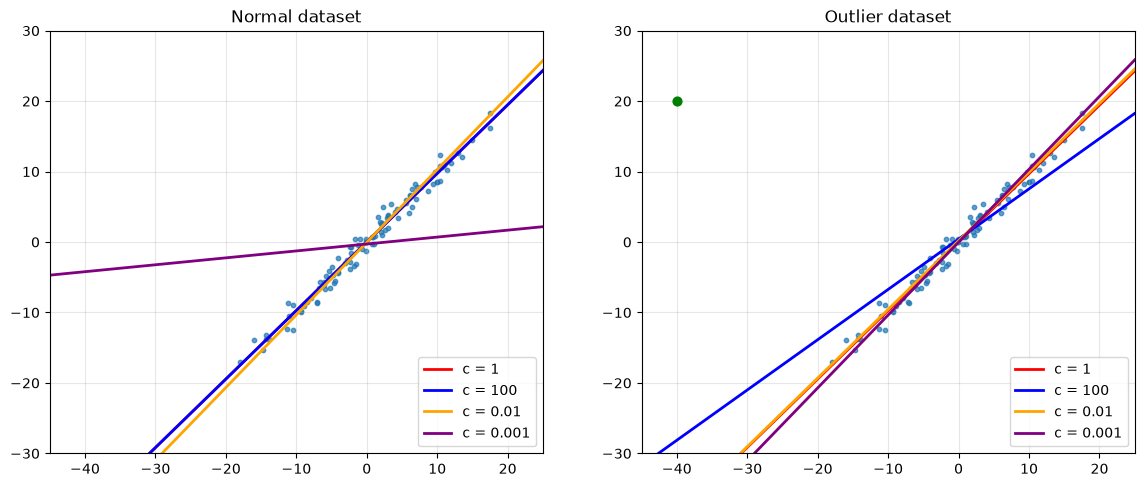

In [281]:
# Approx Claude prompt (summarizing the different steps it took):
#       Can you create a table that shows the different stats from before comparing Cauchy models with c=1, 100, 0.01 and 0.001, add also the LSM for reference
#       Also make plots as the ones from section 1.1 showing the last solution yielded by all the possible models, now not including LSM

#       Further prompts were to clean the presentation and remove further insights it proposed taht we didn't ask for...

c_values = [1, 100, 1/100, 1/1000]
datasets = {"Normal dataset": points, "Outlier dataset": points_one_outlier}
max_iter_c = 100000

sse_used = {"Normal dataset": ("SSE", lambda w0, w1: sse(points, w0, w1)),
            "Outlier dataset": ("SSE 99 points", sse_clean)}

results_c = {}
for dataset_name, data in datasets.items():
    for c_val in c_values:
        scale = min(1, c_val**2)
        f = lambda w: cauchy(data, w[0], w[1], c_val)
        grad_f = lambda w: cauchy_grad(data, w[0], w[1], c_val)
        path_c, alphas_c, n_halvings_c = grad_desc_backtracking(f, grad_f, 0, -0.25, alpha0=0.001/scale, tol=1e-5*scale, max_iter=max_iter_c)
        w0_c, w1_c = path_c[-1]
        results_c[(dataset_name, c_val)] = {"w0": w0_c, "w1": w1_c, "angle": np.degrees(np.arctan(w1_c)), "iters": len(path_c),
                                            "halvings": n_halvings_c, "sse": sse_used[dataset_name][1](w0_c, w1_c)}

# Least Squares for comparison
results_LSM_ref = {"Normal dataset": {"w0": w0_opt_LSM, "w1": w1_opt_LSM, "angle": angle_LSM, "iters": len(path_LSM), "halvings": n_halvings_LSM, "sse": sse_used["Normal dataset"][1](w0_opt_LSM, w1_opt_LSM)},
                   "Outlier dataset": {"w0": w0_opt_LSM_outlier, "w1": w1_opt_LSM_outlier, "angle": angle_LSM_outlier, "iters": len(path_LSM_outlier), "halvings": n_halvings_LSM_outlier, "sse": sse_used["Outlier dataset"][1](w0_opt_LSM_outlier, w1_opt_LSM_outlier)}}

for dataset_name in datasets:
    print(f"{dataset_name}")
    print(f"{'c':>8} | {'w0':>8} | {'w1':>8} | {'Angle (º)':>9} | {'Iterations':>10} | {'Halvings':>8} | {sse_used[dataset_name][0]:>13}")
    print("-" * 82)
    for c_val in c_values:
        r = results_c[(dataset_name, c_val)]
        print(f"{c_val:>8g} | {r['w0']:>8.4f} | {r['w1']:>8.4f} | {r['angle']:>9.2f} | {r['iters']:>10} | {r['halvings']:>8} | {r['sse']:>13.2f}")
    r = results_LSM_ref[dataset_name]
    print(f"{'LSM':>8} | {r['w0']:>8.4f} | {r['w1']:>8.4f} | {r['angle']:>9.2f} | {r['iters']:>10} | {r['halvings']:>8} | {r['sse']:>13.2f}\n")

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
colors = ["red", "blue", "orange", "purple"]
for ax, (dataset_name, data) in zip(axs, datasets.items()):
    ax.scatter(data[:, 0], data[:, 1], alpha=0.7, s=10)
    if dataset_name == "Outlier dataset":
        ax.scatter(*data[1], color="green", s=40, zorder=3)
    for c_val, color in zip(c_values, colors):
        r = results_c[(dataset_name, c_val)]
        ax.axline((0, r["w0"]), slope=r["w1"], color=color, lw=2, label=f"c = {c_val:g}")
    ax.set_xlim(-45, 25)
    ax.set_ylim(-30, 30)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
    ax.set_title(f"{dataset_name}")
plt.show()

Surpisingly, the line $c=0.001$ has ended in a strange spot with the normal database, but if we look correctly at the steps of the model:

In [282]:
c_small = 1/1000

def f_small(w):
    return cauchy(points, w[0], w[1], c_small)

def grad_f_small(w):
    return cauchy_grad(points, w[0], w[1], c_small)

path_small, alphas_small, n_halvings_small = grad_desc_backtracking(f_small, grad_f_small, 0, -0.25, alpha0=0.001/c_small**2, tol=1e-5*c_small**2, max_iter=100000)

print("Iteration |     w0     |     w1     |   dC/dw0   |   dC/dw1   |   |grad|")
print("-" * 76)
for k in range(len(path_small)):
    multiple_of_5 = k % 5 == 0
    one_of_last_5 = k >= len(path_small) - 5
    if multiple_of_5 or one_of_last_5:
        w0 = path_small[k][0]
        w1 = path_small[k][1]
        grad = grad_f_small(path_small[k])
        print(f"{k:9} | {w0:10.6f} | {w1:10.6f} | {grad[0]:10.2e} | {grad[1]:10.2e} | {np.linalg.norm(grad):10.2e}")

Iteration |     w0     |     w1     |   dC/dw0   |   dC/dw1   |   |grad|
----------------------------------------------------------------------------
        0 |   0.000000 |  -0.250000 |   2.48e-04 |  -1.66e-04 |   2.98e-04
        5 |  -0.273245 |   0.086803 |   1.95e-04 |  -6.40e-05 |   2.05e-04
       10 |  -0.273772 |   0.087416 |   9.33e-05 |  -1.39e-04 |   1.68e-04
       15 |  -0.274239 |   0.088100 |   9.78e-05 |  -1.43e-04 |   1.73e-04
       20 |  -0.274724 |   0.088806 |   1.01e-04 |  -1.48e-04 |   1.79e-04
       25 |  -0.275227 |   0.089541 |   1.06e-04 |  -1.54e-04 |   1.87e-04
       30 |  -0.275753 |   0.090309 |   1.11e-04 |  -1.62e-04 |   1.97e-04
       35 |  -0.276309 |   0.091119 |   1.18e-04 |  -1.72e-04 |   2.09e-04
       40 |  -0.276903 |   0.091984 |   1.27e-04 |  -1.86e-04 |   2.25e-04
       45 |  -0.277548 |   0.092925 |   1.41e-04 |  -2.05e-04 |   2.49e-04
       50 |  -0.278273 |   0.093980 |   1.62e-04 |  -2.36e-04 |   2.87e-04
       55 |  -0.279138 | 

As we can see, a minimum has been reached! Using such a small c means thatm if we recall the gradient

$$
\nabla C =
\begin{pmatrix}
\dfrac{\partial C}{\partial w_0} \\[2ex]
\dfrac{\partial C}{\partial w_1}
\end{pmatrix}
=
\begin{pmatrix}
\displaystyle\sum_{i=1}^{m} \frac{w_1 x_i + w_0 - y_i}{1 + \left(\frac{w_1 x_i + w_0 - y_i}{c}\right)^{2}} \\[4ex]
\displaystyle\sum_{i=1}^{m} \frac{w_1 x_i + w_0 - y_i}{1 + \left(\frac{w_1 x_i + w_0 - y_i}{c}\right)^{2}}\,x_i
\end{pmatrix}
$$

We see that having $c$ being small, will make each summand of the gradient be small, in the case of $c=0.001$, small enough to be stuck in a valley of a local minima, just as we saw in practise 2.

We also see that using a small $c$, in this case $c=0.01$ will mean, as summands are small, to take more steps to reach the solution. This can be ascertained in the table, where three times more steps are needed to reach a good (based on the tolerance) solution. But we can see that in both cases, they reached a robust solution in the outlier case, just as $c = 1$. 

By contrast, $c = 100$ reached a closer solution to $c = 1$ and the Least Squares method in the normal dataset. This is shown by the overlapping of both lines in the plot, aswell as the similar values $w_{0}$ and $w_{1}$ reached at the last step. The "bad" performance that stands out in the outlier dataset is a consequence of what we explained before. If $c$ is big, then $(\frac{u}{c})^2$ is small, this means that $\frac{c^2}{2}\log(1+(\frac{u}{c})^{2}) \sim \frac{c^{2}}{2}(\frac{u}{c})^{2} = \frac{1}{2}u^{2}$ which is the Least Squares method, therefore being affected by outliers.

Now we will see a histogram of the error function, to see it's contribution to $Q$. As we have just seen it is important to not have $\frac{u}{c}$ "too small" or "too big" as the model can miss the global minimum or be highly influenced by outliers, respectively. We are more interestered in the second statement, thus we will look at how many points we have $|u| \leq c$ as these point contribute more for $Q$.

Median |u| = 0.861
Largest |u| = 58.871 (the outlier)
--------------------------------------------------
c = 1: 60 points with |u| <= c
c = 100: 100 points with |u| <= c
c = 0.01: 0 points with |u| <= c
c = 0.001: 0 points with |u| <= c
--------------------------------------------------
c = 1 (red): rho(100) = 4.605
c = 100 (blue): rho(100) = 3466
c = 0.01 (orange): rho(100) = 0.000921
c = 0.001 (purple): rho(100) = 1.151e-05


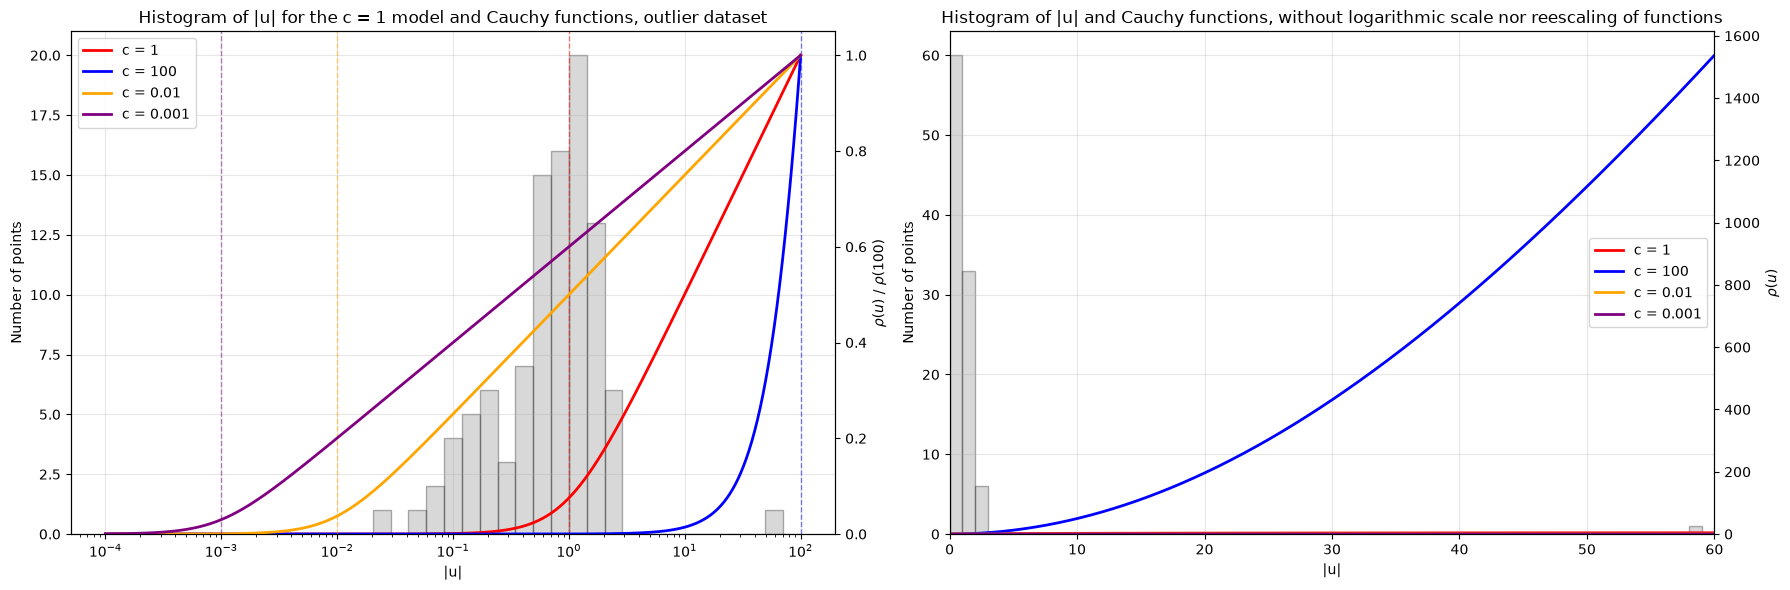

In [283]:
# Approx Claude prompt (summarizing the different steps it took):
#       Compute |u| and print how many points have |u| <= c and rho(100) for c = 1, 100, 0.01 and 0.001.
#       Make two plots: 1. the histogram of |u| on a log axis with the Cauchy functions and a dashed line at each c
#       2. the same histogram on a linear axis up to 60 with the real rho(u).
#
#       Further prompts were to adjust the axes, the scaling of the functions and the printed values...

# Residuals of the c = 1 model on the dataset with the outlier (section 2.4)
u = w1_opt_Cauchy_outlier * points_one_outlier[:, 0] + w0_opt_Cauchy_outlier - points_one_outlier[:, 1]
abs_u = np.abs(u)

c_hist = [1, 100, 1/100, 1/1000]
colors = ["red", "blue", "orange", "purple"]

print(f"Median |u| = {np.median(abs_u):.3f}")
print(f"Largest |u| = {np.max(abs_u):.3f} (the outlier)")

print("-" * 50)

for c_val in c_hist:
    n_inliers = np.sum(abs_u <= c_val)
    print(f"c = {c_val:g}: {n_inliers} points with |u| <= c")

print("-" * 50)

for c_val, color in zip(c_hist, colors):
    rho_100 = ((c_val**2)/2) * np.log(1 + (100/c_val)**2)
    print(f"c = {c_val:g} ({color}): rho(100) = {rho_100:.4g}")

fig, axs = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1
# We use logarithmic scale for |u|
bins_log = np.logspace(-4, 2, 40)
u_plot_log = np.logspace(-4, 2, 500)

# Histogram in the background
axs[0].hist(abs_u, bins=bins_log, color="gray", edgecolor="black", alpha=0.3)
axs[0].set_xscale("log")
axs[0].set_xlabel("|u|")
axs[0].set_ylabel("Number of points")
axs[0].grid(alpha=0.3)

# Cauchy functions on a second y axis. We divide each one by its value at |u| = 100 to compare only their shapes
ax_rho_log = axs[0].twinx()
for c_val, color in zip(c_hist, colors):
    rho = ((c_val**2)/2) * np.log(1 + (u_plot_log/c_val)**2)
    rho_max = ((c_val**2)/2) * np.log(1 + (100/c_val)**2)
    ax_rho_log.plot(u_plot_log, rho / rho_max, color=color, lw=2, label=f"c = {c_val:g}")
    ax_rho_log.axvline(c_val, color=color, lw=1, ls="--", alpha=0.5)
ax_rho_log.set_ylabel(r"$\rho(u)$ / $\rho(100)$")
ax_rho_log.set_ylim(0, 1.05)
ax_rho_log.legend(loc="upper left")
axs[0].set_title("Histogram of |u| for the c = 1 model and Cauchy functions, outlier dataset")

# Plot 2: histogram in the background and the Cauchy functions, linear x axis
u_max = 60
bins = np.linspace(0, u_max, 61)
u_plot = np.linspace(0, u_max, 2000)

axs[1].hist(abs_u, bins=bins, color="gray", edgecolor="black", alpha=0.3)
axs[1].set_xlim(0, u_max)
axs[1].set_xlabel("|u|")
axs[1].set_ylabel("Number of points")
axs[1].grid(alpha=0.3)

# Cauchy functions on a second y axis
ax_rho = axs[1].twinx()
for c_val, color in zip(c_hist, colors):
    rho = ((c_val**2)/2) * np.log(1 + (u_plot/c_val)**2)
    ax_rho.plot(u_plot, rho, color=color, lw=2, label=f"c = {c_val:g}")
ax_rho.set_ylim(bottom=0)
ax_rho.set_ylabel(r"$\rho(u)$")
ax_rho.legend(loc="center right")
axs[1].set_title("Histogram of |u| and Cauchy functions, without logarithmic scale nor reescaling of functions")

plt.tight_layout()
plt.show()

To understand where each Cauchy function stops behaving quatraticly, we study its convexity. We already computed the first derivative:

$$
\rho'(u) = \frac{u}{1 + \left(\frac{u}{c}\right)^{2}} = \frac{c^{2}u}{c^{2} + u^{2}}
$$

Differentiating again:

$$
\rho''(u) = \frac{c^{2}(c^{2} + u^{2}) - c^{2}u \cdot 2u}{(c^{2} + u^{2})^{2}} = \frac{c^{2}(c^{2} - u^{2})}{(c^{2} + u^{2})^{2}}
$$

The sign of $\rho''(u)$ is the sign of $c^{2} - u^{2}$:

- If $|u| < c$, then $\rho''(u) > 0$ and $\rho$ is convex. Here the Cauchy function behaves as a quadratic function.
- If $|u| = c$, then $\rho''(u) = 0$, so $u = \pm c$ are the inflection points.
- If $|u| > c$, then $\rho''(u) < 0$ and $\rho$ is concave. Here the function grows logarithmically.

Let's zoom on the plots to see this, at the left of $|u| = c$ the function will behave quadraticly:

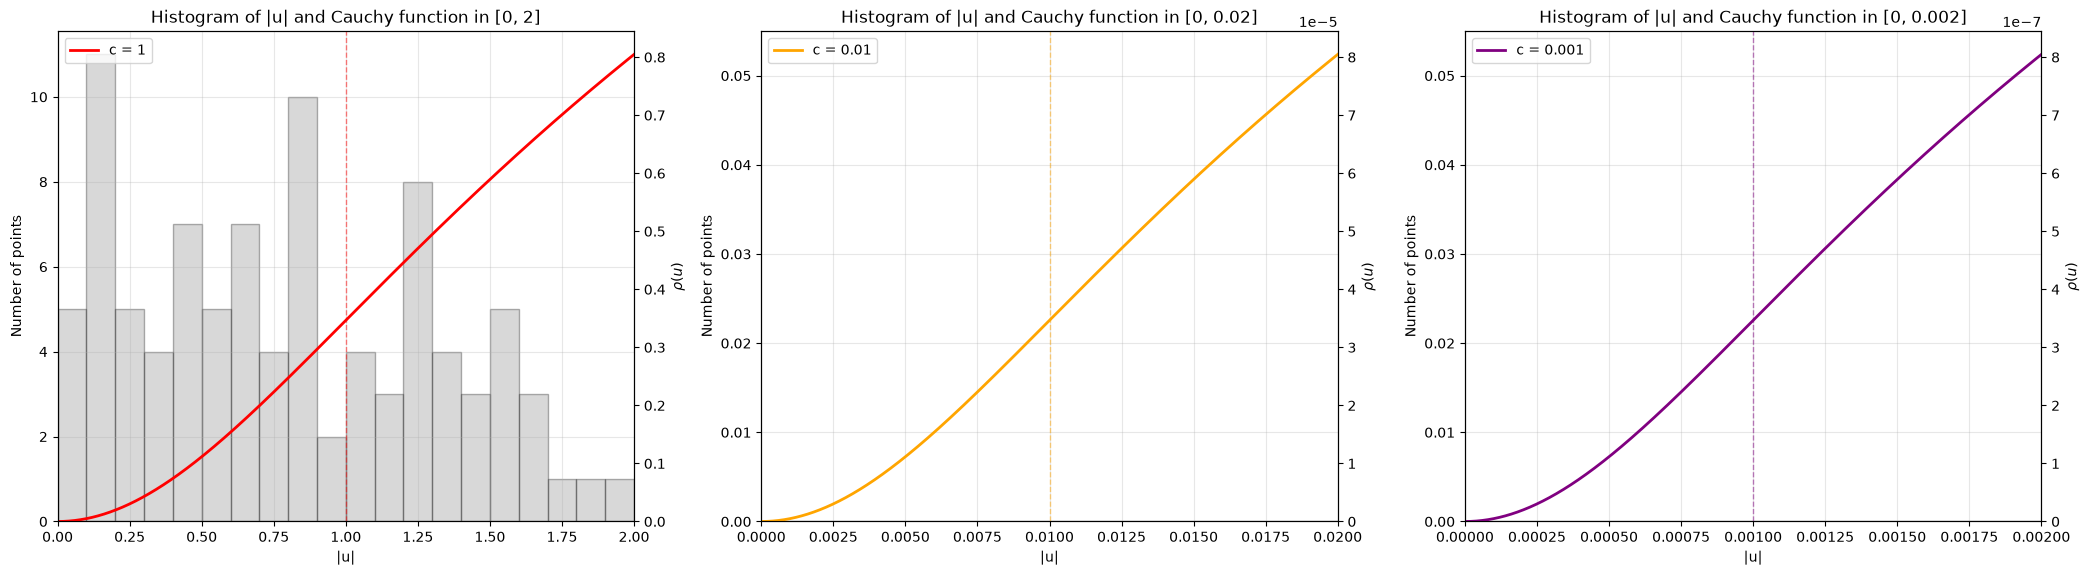

In [284]:
# Residuals of the c = 1 model on the dataset with the outlier (section 2.4)
u = w1_opt_Cauchy_outlier * points_one_outlier[:, 0] + w0_opt_Cauchy_outlier - points_one_outlier[:, 1]
abs_u = np.abs(u)

c_zoom = [1, 1/100, 1/1000]
u_max_values = [2, 0.02, 0.002]
colors = ["red", "orange", "purple"]

fig, axs = plt.subplots(1, 3, figsize=(21, 6))

for ax_hist, c_val, u_max, color in zip(axs, c_zoom, u_max_values, colors):
    bins = np.linspace(0, u_max, 21)
    u_plot = np.linspace(0, u_max, 2000)

    # Histogram in the background
    ax_hist.hist(abs_u, bins=bins, color="gray", edgecolor="black", alpha=0.3)
    ax_hist.set_xlim(0, u_max)
    ax_hist.set_ylim(bottom=0)
    ax_hist.set_xlabel("|u|")
    ax_hist.set_ylabel("Number of points")
    ax_hist.grid(alpha=0.3)

    # Cauchy function on a second y axis, with a dashed line at u = c
    ax_rho = ax_hist.twinx()
    rho = ((c_val**2)/2) * np.log(1 + (u_plot/c_val)**2)
    ax_rho.plot(u_plot, rho, color=color, lw=2, label=f"c = {c_val:g}")
    ax_rho.axvline(c_val, color=color, lw=1, ls="--", alpha=0.5)
    ax_rho.set_ylim(bottom=0)
    ax_rho.set_ylabel(r"$\rho(u)$")
    ax_rho.legend(loc="upper left")

    ax_hist.set_title(f"Histogram of |u| and Cauchy function in [0, {u_max:g}]")

plt.tight_layout()
plt.show()

Therefore, $c$ is the threshold between "inliers" and "outliers": points with $|u| \leq c$ are in the convex part and are treated as in the Least Squares method, "outliers"; whilst points with $|u| > c$ are in the concave part and have less and less influence, "inliers". So by choosing a small $c$, supposed outliers will have a small $|u|$ still, so they will contribute similarly as an "inlier".

### 2.6 Checking that the Cauchy function is not perfect

The Cauchy function is not robust for any number of outliers. To check it, we will use $c = 1$ and $c = \frac{1}{100}$ with four datasets with a growing number of outliers: the one outlier dataset from section 1.2, the five outliers dataset and two new datasets with fifteen and twenty outliers. For the fifteen outliers dataset we keep the five outliers and move ten more points to $\left[-40,-8\right]$, $\left[-37,-35\right]$, $\left[-28,-42\right]$, $\left[-10,-21\right]$, $\left[-30,-1\right]$, $\left[35,1\right]$, $\left[7,29\right]$, $\left[27,-34\right]$, $\left[30,41\right]$ and $\left[41,28\right]$. For the twenty outliers dataset we keep these fifteen and move five more points to $\left[-20,30\right]$, $\left[20,-25\right]$, $\left[-42,5\right]$, $\left[15,-40\right]$ and $\left[38,-10\right]$.

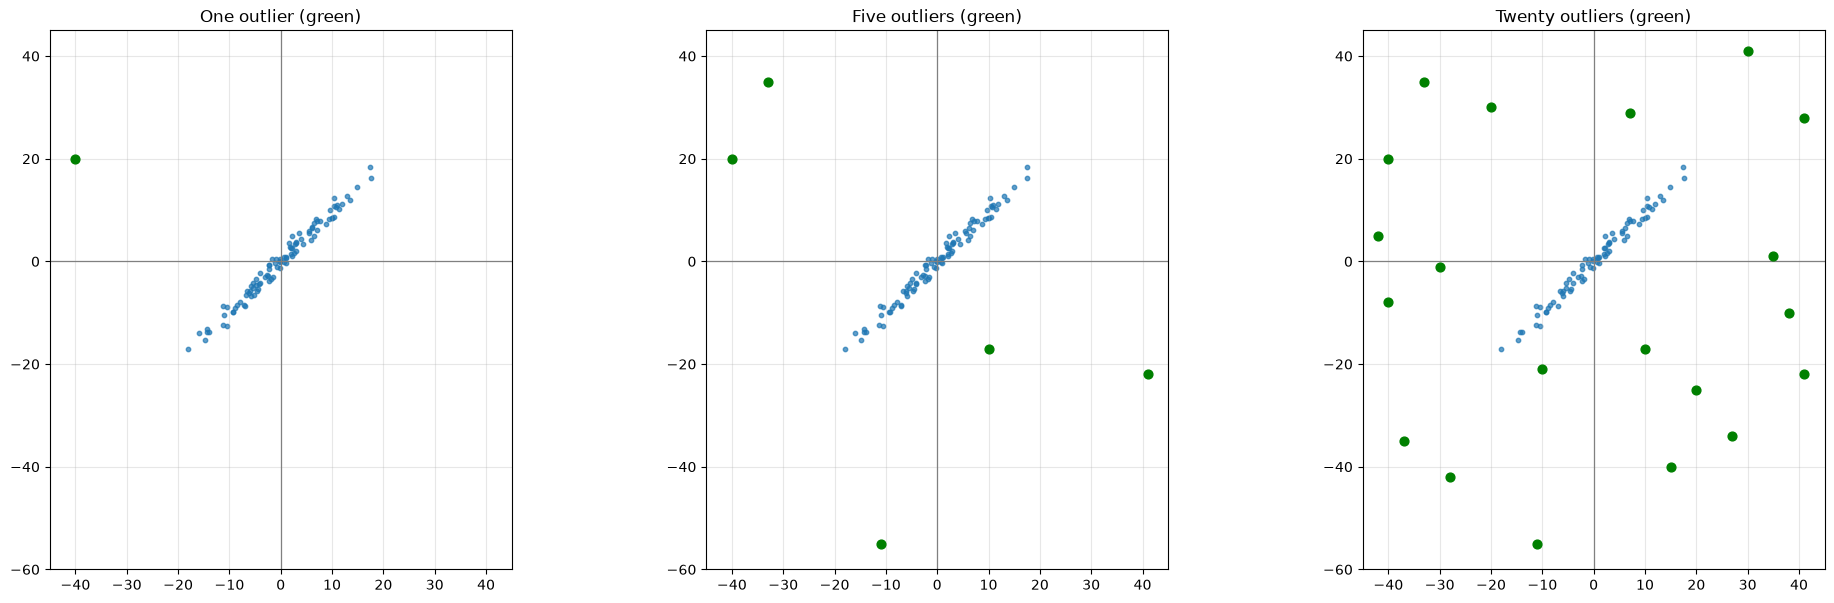

In [285]:
points_20_outliers = points_more_outliers.copy()
points_20_outliers[6] = [-40,-8]
points_20_outliers[7] = [-37,-35]
points_20_outliers[8] = [-28,-42]
points_20_outliers[9] = [-10,-21]
points_20_outliers[10] = [-30,-1]
points_20_outliers[11] = [35,1]
points_20_outliers[12] = [7,29]
points_20_outliers[13] = [27,-34]
points_20_outliers[14] = [30,41]
points_20_outliers[15] = [41,28]
points_20_outliers[16] = [-20,30]
points_20_outliers[17] = [20,-25]
points_20_outliers[18] = [-42,5]
points_20_outliers[19] = [15,-40]
points_20_outliers[20] = [38,-10]
outliers_20_idx = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]

datasets_26 = {"One outlier": (points_one_outlier, [1]),
               "Five outliers": (points_more_outliers, outliers_idx),
               "Twenty outliers": (points_20_outliers, outliers_20_idx)}

fig, axs = plt.subplots(1, 3, figsize=(24, 7))
for ax, (dataset_name, (data, idx)) in zip(axs, datasets_26.items()):
    ax.scatter(data[:, 0], data[:, 1], alpha=0.7, s=10)
    ax.scatter(data[idx, 0], data[idx, 1], color="green", s=40, zorder=3)
    ax.axhline(0, color="gray", lw=0.9)
    ax.axvline(0, color="gray", lw=0.9)
    ax.set_xlim(-45, 45)
    ax.set_ylim(-60, 45)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_title(f"{dataset_name} (green)")
plt.show()

Now we fit the model with Least Squares, for reference, and with the Cauchy function with $c = 1$ and $c = \frac{1}{100}$ for each dataset. As in section 2.4, to compare the models we use the sum of squared distances of the points that are not outliers.

         Dataset |   Method |       w0 |       w1 | Angle (º) | Iterations | SSE inliers |    |grad|
-----------------------------------------------------------------------------------------------------
     One outlier |      LSM |   0.4819 |   0.6670 |     33.70 |        552 |      702.25 |  4.36e-05
     One outlier |    c = 1 |  -0.0055 |   0.9716 |     44.18 |        398 |      115.60 |  9.75e-06
     One outlier | c = 0.01 |   0.1829 |   0.9744 |     44.26 |       2433 |      118.59 |  5.57e-08
-----------------------------------------------------------------------------------------------------
   Five outliers |      LSM |  -0.1869 |   0.3157 |     17.52 |        969 |     2659.11 |  9.67e-05
   Five outliers |    c = 1 |  -0.0148 |   0.9682 |     44.07 |        457 |      113.26 |  9.78e-06
   Five outliers | c = 0.01 |  -0.0526 |  -0.2145 |    -12.10 |         51 |     8426.19 |  4.78e-09
-----------------------------------------------------------------------------------------

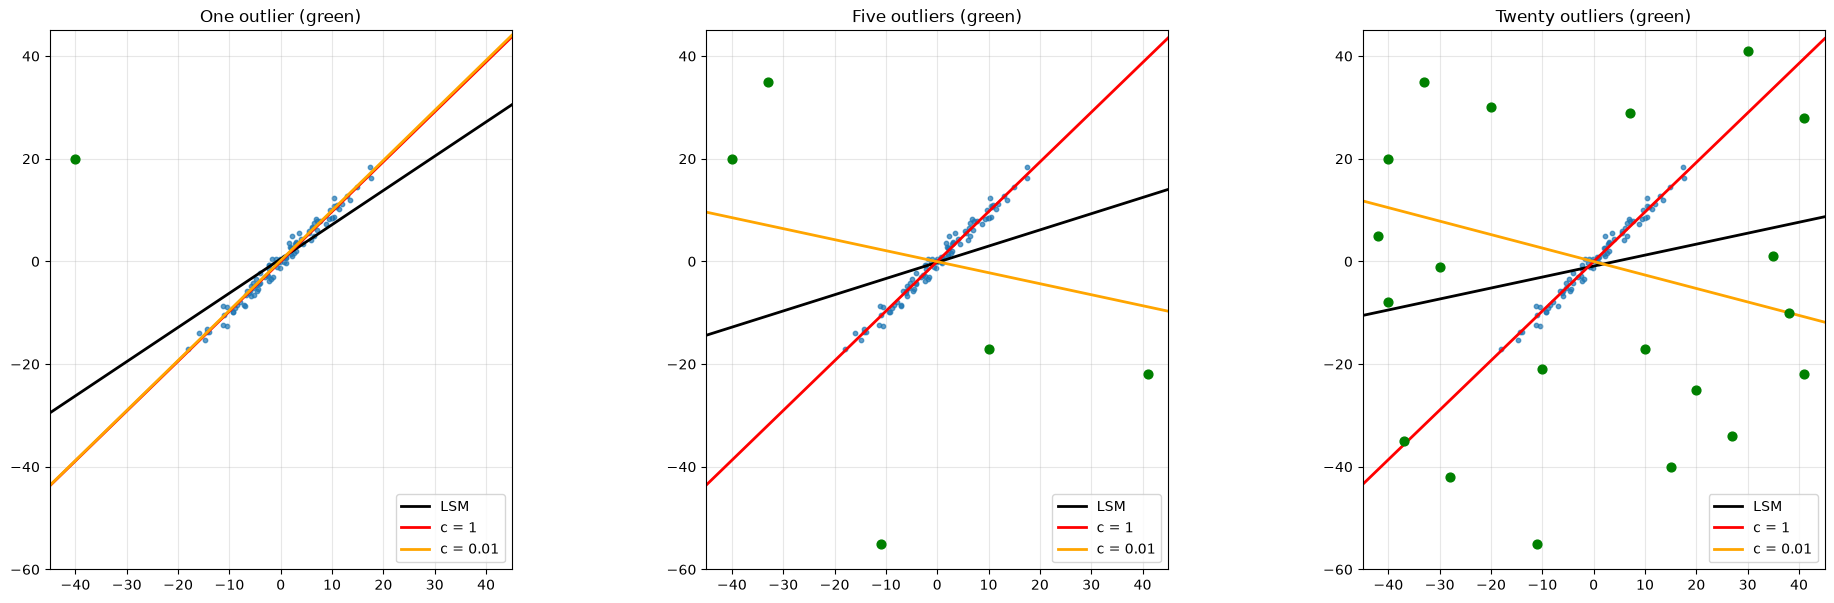

In [286]:
c_26 = [1, 1/100]
colors_26 = {"LSM": "black", "c = 1": "red", "c = 0.01": "orange"}

# Sum of squared distances of the points that are not outliers
def sse_inliers(data, idx, w0, w1):
    mask = np.ones(len(data), dtype=bool)
    mask[idx] = False
    return np.sum((w1 * data[mask, 0] + w0 - data[mask, 1])**2)

results_26 = {}
grad_norms_26 = {}
for dataset_name, (data, idx) in datasets_26.items():
    # Least Squares
    def f_lsm_26(w):
        return LSM(data, w[0], w[1])

    def grad_f_lsm_26(w):
        return LSM_grad(data, w[0], w[1])

    path_26, alphas_26, n_halvings_26 = grad_desc_backtracking(f_lsm_26, grad_f_lsm_26, 0, -0.25)
    results_26[(dataset_name, "LSM")] = path_26
    grad_norms_26[(dataset_name, "LSM")] = np.linalg.norm(grad_f_lsm_26(path_26[-1]))

    # Cauchy, with alpha0 and tol scaled by c^2 as in section 2.5
    for c_val in c_26:
        def f_cauchy_26(w):
            return cauchy(data, w[0], w[1], c_val)

        def grad_f_cauchy_26(w):
            return cauchy_grad(data, w[0], w[1], c_val)

        scale = min(1, c_val**2)
        path_26, alphas_26, n_halvings_26 = grad_desc_backtracking(f_cauchy_26, grad_f_cauchy_26, 0, -0.25, alpha0=0.001/scale, tol=1e-5*scale, max_iter=100000)
        results_26[(dataset_name, f"c = {c_val:g}")] = path_26
        grad_norms_26[(dataset_name, f"c = {c_val:g}")] = np.linalg.norm(grad_f_cauchy_26(path_26[-1]))

print(f"{'Dataset':>16} | {'Method':>8} | {'w0':>8} | {'w1':>8} | {'Angle (º)':>9} | {'Iterations':>10} | {'SSE inliers':>11} | {'|grad|':>9}")
print("-" * 101)
for dataset_name, (data, idx) in datasets_26.items():
    for method in colors_26:
        path_26 = results_26[(dataset_name, method)]
        w0, w1 = path_26[-1]
        angle_26 = np.degrees(np.arctan(w1))
        print(f"{dataset_name:>16} | {method:>8} | {w0:>8.4f} | {w1:>8.4f} | {angle_26:>9.2f} | {len(path_26):>10} | {sse_inliers(data, idx, w0, w1):>11.2f} | {grad_norms_26[(dataset_name, method)]:>9.2e}")
    print("-" * 101)

fig, axs = plt.subplots(1, 3, figsize=(24, 7))
for ax, (dataset_name, (data, idx)) in zip(axs, datasets_26.items()):
    ax.scatter(data[:, 0], data[:, 1], alpha=0.7, s=10)
    ax.scatter(data[idx, 0], data[idx, 1], color="green", s=40, zorder=3)
    for method, color in colors_26.items():
        w0, w1 = results_26[(dataset_name, method)][-1]
        ax.axline((0, w0), slope=w1, color=color, lw=2, label=method)
    ax.set_xlim(-45, 45)
    ax.set_ylim(-60, 45)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
    ax.set_title(f"{dataset_name} (green)")
plt.show()

As we can see, problems with the Cauchy function arise, as before, backtracking gradient descent reaches local minimums that, whilst minimizing the gradient, do not offer the best model to our dataset. And the model has become "stuck" with a $c$ 10 times bigger than before.

It is feasable to conlcude that with enough outliers, the model intrinsically has more solutions to the problem that do not yield a solution. There is a balance between, being affected by outliers, therefore the model is not as accurate; and being trapped by outliers, ending up in a false solution.

I read every conclusion and compared it with the current outputs. Several of them look strange. In order of importance:

## 1. Inliers and outliers are swapped (the cell after the zoom plots)

> points with |u| ≤ c are in the convex part and are treated as in the Least Squares method, **"outliers"**; whilst points with |u| > c are in the concave part and have less and less influence, **"inliers"**.

This is the wrong way round. Points with |u| ≤ c are the inliers, and points with |u| > c are the outliers. The next sentence is also wrong:

> So by choosing a small c, supposed outliers will have a small |u| still, so they will contribute similarly as an "inlier".

With a small c, it's the other way round: even the good points have |u| > c, so **every point is treated as an outlier**. Your printed counts show this: 0 points with |u| ≤ c for both c = 0.01 and c = 0.001.

## 2. Out-of-date numbers from before the seed (two cells)

**One-outlier conclusions (1.2).** These still describe the data from before you set the seed:

| The text says | Current outputs |
|---|---|
| w₁ = 0.9643 (43.96º), w₀ = 0.1447 | w₁ = 0.9730 (44.22º), w₀ = 0.0141 |
| rotates about 12º, slope drops about 30% | about 10.5º, −31% |
| outlier contributes about ½·58² ≈ 1700, 20 times the rest (73.24) | about 1735, about 30 times the rest (56.58) |
| Q +1700%; outlier ≈ 970, other 99 ≈ 390, five times worse | Q +2349%; outlier ≈ 1067, other 99 ≈ 351, about 6 times worse |
| **"4 times as many iterations, 561 to 2331"** | **466 → 552, only +18%** |

The last row matters most: since the stopping fix, the outlier no longer multiplies the number of iterations.

**"Comparison between LSM and Cauchy" (after 2.4).** The whole cell uses the old numbers, and some of its conclusions have reversed:
- *"Cauchy took longer but used just one halving… Least Squares reached it faster"*: Cauchy now takes **330 iterations against 466** for least squares, with **0 halvings**. Cauchy is the faster one now.
- SSE "187.47 against 187.63": it's now **115.58 against 115.58**.
- Outlier case: least squares now gives 0.4819 / 0.6670 / 33.70º (not 0.8114 / 0.5841 / 30.29º), and Cauchy gives −0.0055 / 0.9716 / 44.18º (not −0.1118 / 0.9896 / 44.70º).
- *"Least Squares needs 2474 iterations, more than 3 times…"*: it's now **552, +18%**. Cauchy takes 398, not 931.
- Q goes from 57.92 to 1418.31 for least squares, not 94.54 to 1367.37, and from 30.62 to 34.57 for Cauchy, not 36.92 to 40.54. SSE 99 is 702.25 against 115.58, about 6 times worse, not 924.01 against 187.47.

## 3. The 2.6 intro doesn't match the code any more

The intro still talks about "two new datasets with fifteen and twenty outliers". The data cell now builds only `points_20_outliers` directly from the five-outlier dataset, and the table has One, Five and Twenty. Either remove the fifteen-outlier sentence or add that dataset back.

## 4. The 2.6 conclusion says more than the results show

> problems with the Cauchy function arise… It is feasible to conclude that with enough outliers, the model intrinsically has more solutions…

In your table only **c = 0.01** fails (−12º and −15º). **c = 1 stays at about 44º with 20 outliers** (SSE 95.28, the best of all). The conclusion should say that c = 1 was still robust with 20% scattered outliers, and that the failures are c = 0.01 getting stuck in local minima. The phrase "more solutions to the problem that do not yield a solution" is also hard to follow; "more local minima that are not the right model" would be clearer.

## 5. The reasoning behind the c = 0.001 local minimum (2.5)

> having c being small, will make each summand of the gradient be small… small enough to be stuck in a valley of a local minima

Small gradient terms only make the descent slow. What gets it stuck is that **C(w) is no longer convex**: every point is in the concave part, and every pair of points creates a narrow valley (your section on the second derivative explains this). The text should give the non-convexity as the reason.

## 6. Smaller issues

- **The histogram intro** says points with |u| ≤ c "contribute more for Q". It's the opposite: each of those points contributes little (u²/2 is small). What's true is that they are the ones that matter for the fit, because they still pull with a least-squares weight.
- **`$8600%$` in the five-outlier conclusions:** inside LaTeX, `%` starts a comment and can break how that line renders. Write `8600\%` or put the `%` outside the `$...$`.
- **"With only 5 of the points being outliers"** should be "5%" or "5 of the 100 points".
- **Typos:** "Surpisingly", "thatm", "quatraticly", "quadraticly", "it's contribution" (should be "its"), "interestered", "aswell", "feasable", "conlcude".